### Import Library

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix
)

### Memuat data siap pakai dari hasil Tahap 6

In [2]:
X_train, X_test, y_train, y_test = joblib.load('../dataset/step_06_ready_for_model.pkl')
print("Data berhasil dimuat! Ukuran X_train:", X_train.shape)

Data berhasil dimuat! Ukuran X_train: (3891, 12)


### Menyiapkan Batas Kategori Harga (Murah, Sedang, Mahal)


In [3]:
# Batas kuartil diambil dari y_train (0 = Murah, 1 = Sedang, 2 = Mahal)
_, bins = pd.qcut(y_train, q=3, retbins=True, labels=[0, 1, 2])
bins[0], bins[-1] = -float('inf'), float('inf')

### Mengubah y_train dan y_test menjadi kategori kelas (0, 1, 2)

In [4]:
y_train_kelas = pd.cut(y_train, bins=bins, labels=[0, 1, 2]).astype(int)
y_test_kelas  = pd.cut(y_test, bins=bins, labels=[0, 1, 2]).astype(int)

### Mencari Nilai K Terbaik Berdasarkan Accuracy

In [5]:
k_values = range(1, 16)
acc_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train_kelas)
    y_pred_temp = knn_temp.predict(X_test)
    acc_scores.append(accuracy_score(y_test_kelas, y_pred_temp))

best_k = k_values[np.argmax(acc_scores)]
print(f"Nilai K terbaik adalah: {best_k} dengan Accuracy: {max(acc_scores):.4f}")

Nilai K terbaik adalah: 7 dengan Accuracy: 0.6886


### Visualisasi nilai K vs Accuracy

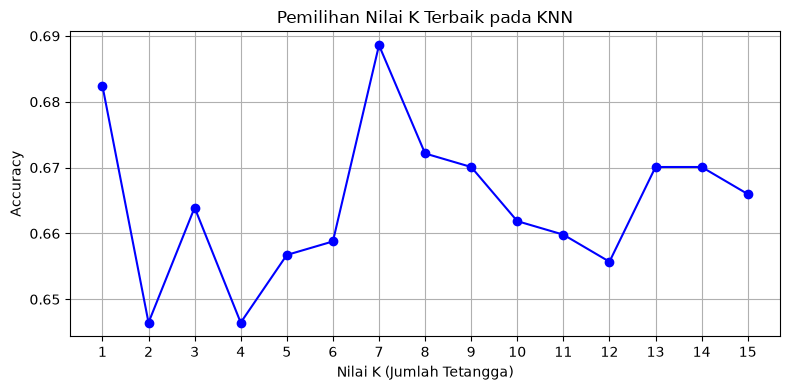

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(k_values, acc_scores, marker='o', linestyle='-', color='b')
plt.title('Pemilihan Nilai K Terbaik pada KNN')
plt.xlabel('Nilai K (Jumlah Tetangga)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()

### Melatih Model KNN Final

In [7]:
start_time = time.perf_counter()

model_knn = KNeighborsClassifier(n_neighbors=best_k)
model_knn.fit(X_train, y_train_kelas)
y_pred_knn = model_knn.predict(X_test)


end_time = time.perf_counter()

waktu_knn = end_time - start_time

print("Model Berhasil Dibuat!")
print(f"Waktu Eksekusi Model KNN: {waktu_knn:.4f} detik")

Model Berhasil Dibuat!
Waktu Eksekusi Model KNN: 0.0583 detik


### Evaluasi

In [8]:
acc_knn = accuracy_score(y_test_kelas, y_pred_knn)
prec_knn = precision_score(y_test_kelas, y_pred_knn, average='weighted')
rec_knn = recall_score(y_test_kelas, y_pred_knn, average='weighted')
f1_knn = f1_score(y_test_kelas, y_pred_knn, average='weighted')

print("=== HASIL EVALUASI MODEL KNN ===")
print(f"1. Accuracy       : {acc_knn:.4f} ({acc_knn*100:.2f}%)")
print(f"2. Precision      : {prec_knn:.4f}")
print(f"3. Recall         : {rec_knn:.4f}")
print(f"4. F1-Score       : {f1_knn:.4f}")
print(f"5. Waktu Eksekusi : {waktu_knn:.4f} detik\n")



=== HASIL EVALUASI MODEL KNN ===
1. Accuracy       : 0.6886 (68.86%)
2. Precision      : 0.6905
3. Recall         : 0.6886
4. F1-Score       : 0.6895
5. Waktu Eksekusi : 0.0583 detik



### Visualisasi Confusion Matrix

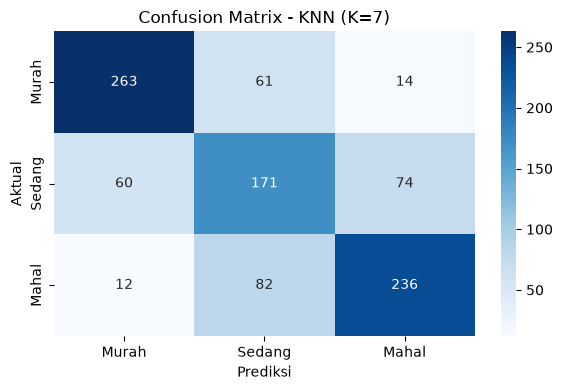

In [9]:
cm_knn = confusion_matrix(y_test_kelas, y_pred_knn)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Murah', 'Sedang', 'Mahal'], 
            yticklabels=['Murah', 'Sedang', 'Mahal'])
plt.title(f'Confusion Matrix - KNN (K={best_k})')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

### Menyimpan Hasil KNN

In [10]:
hasil_knn = {
    'Model': 'KNN',
    'Accuracy': acc_knn,
    'Precision': prec_knn,
    'Recall': rec_knn,
    'F1-Score': f1_knn,
    'Waktu (Detik)': waktu_knn,
    'y_test_kelas': y_test_kelas,
    'y_pred_kelas': y_pred_knn
}

joblib.dump(hasil_knn, 'hasil_knn.pkl')
print("Hasil evaluasi KNN berhasil disimpan ke 'klasifikasi_model/hasil_knn.pkl'!")

Hasil evaluasi KNN berhasil disimpan ke 'klasifikasi_model/hasil_knn.pkl'!
